# Experiment 17: Mobile Price Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement **Mobile Price Prediction** using appropriate machine-learning algorithms (classification into price ranges 0-3: low, medium, high, very high).

## Note on the data
A **synthetic mobile-phones data set** with the same columns as the Kaggle *Mobile Price Classification* data (battery power, RAM, memory, pixel resolution, ...) is generated with a fixed seed. To use the real `train.csv`, replace the data cell with `df = pd.read_csv('train.csv')`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(1)
n = 2000
df = pd.DataFrame({
    'battery_power': rng.integers(500, 2000, n),
    'blue': rng.integers(0, 2, n),
    'clock_speed': rng.uniform(0.5, 3.0, n).round(1),
    'dual_sim': rng.integers(0, 2, n),
    'fc': rng.integers(0, 20, n),
    'four_g': rng.integers(0, 2, n),
    'int_memory': rng.integers(2, 64, n),
    'mobile_wt': rng.integers(80, 200, n),
    'n_cores': rng.integers(1, 9, n),
    'pc': rng.integers(0, 20, n),
    'px_height': rng.integers(0, 1960, n),
    'px_width': rng.integers(500, 1998, n),
    'ram': rng.integers(256, 3998, n),
    'talk_time': rng.integers(2, 20, n),
    'wifi': rng.integers(0, 2, n),
})
score = (0.0012 * df.ram + 0.0006 * df.battery_power + 0.0004 * df.px_height + 0.0003 * df.px_width
         + 0.02 * df.int_memory + 0.3 * df.four_g + 0.1 * df.n_cores + rng.normal(0, 0.12, n))
df['price_range'] = pd.qcut(score, 4, labels=[0, 1, 2, 3]).astype(int)
df.to_csv('mobile_price_synthetic.csv', index=False)
print(df.shape); print(df['price_range'].value_counts().sort_index())
df.head()

(2000, 16)
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,mobile_wt,n_cores,pc,px_height,px_width,ram,talk_time,wifi,price_range
0,1209,1,1.2,1,13,1,42,142,2,4,1921,1093,1965,4,0,2
1,1267,1,0.5,1,0,0,24,163,4,11,1840,1466,2253,10,1,2
2,1632,0,0.8,1,14,1,60,167,6,8,1755,1417,604,19,1,1
3,1925,1,0.8,1,14,0,61,89,8,0,1216,717,2855,13,0,3
4,552,1,1.6,1,2,1,18,163,8,7,1573,1270,2290,12,0,2


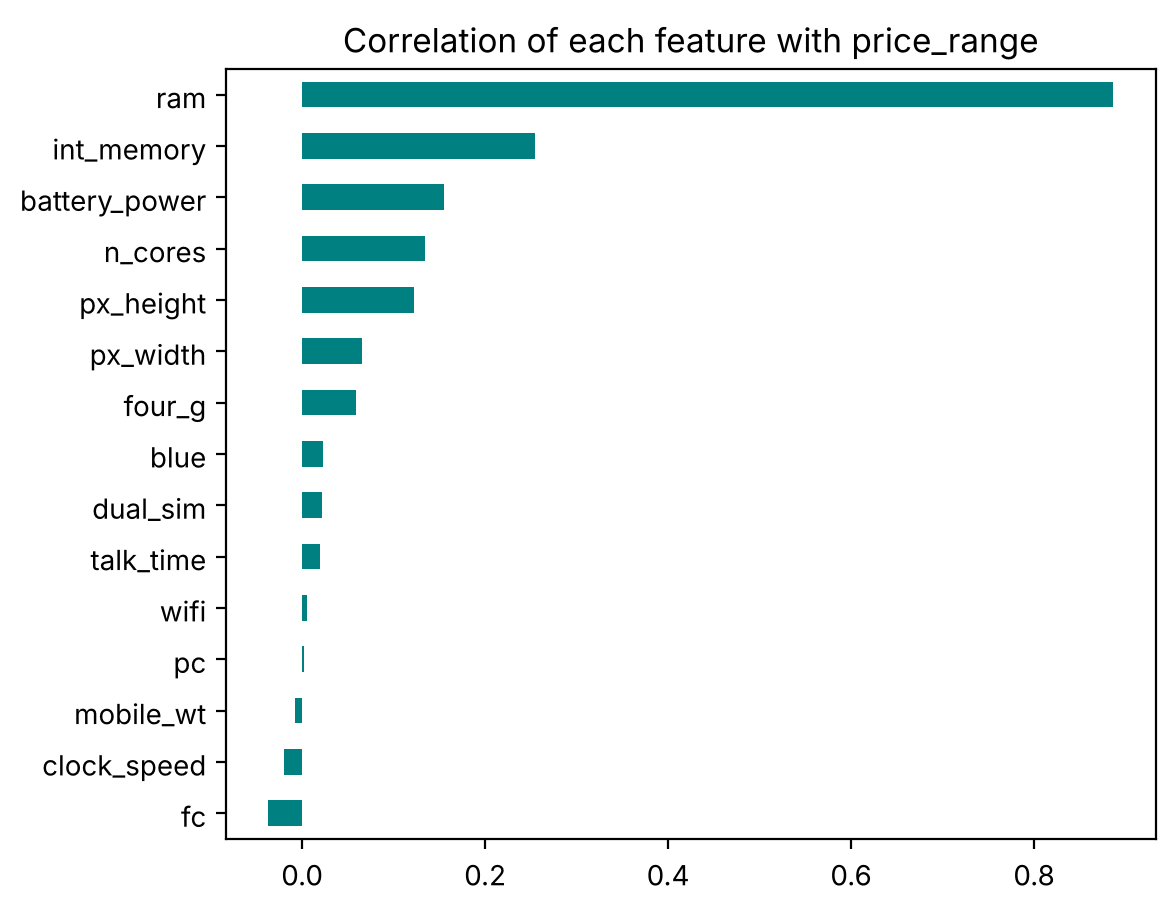

In [2]:
corr = df.corr()['price_range'].drop('price_range').sort_values()
plt.figure(figsize=(6, 5)); corr.plot.barh(color='teal')
plt.title('Correlation of each feature with price_range'); plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X, y = df.drop(columns='price_range'), df['price_range']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'K-NN': make_pipeline(StandardScaler(), KNeighborsClassifier(7)),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
}
acc = {}
for name, m in models.items():
    m.fit(X_train, y_train); acc[name] = accuracy_score(y_test, m.predict(X_test))
print(pd.Series(acc).round(4).sort_values(ascending=False).to_string())
best_name = max(acc, key=acc.get); best = models[best_name]
print('\nBest model:', best_name)

Logistic Regression    0.92
Random Forest          0.80
Decision Tree          0.76
K-NN                   0.53

Best model: Logistic Regression


               precision    recall  f1-score   support

      Low (0)       0.99      0.92      0.95       100
   Medium (1)       0.87      0.92      0.89       100
     High (2)       0.86      0.92      0.89       100
Very high (3)       0.98      0.92      0.95       100

     accuracy                           0.92       400
    macro avg       0.92      0.92      0.92       400
 weighted avg       0.92      0.92      0.92       400

Confusion matrix (rows = actual, cols = predicted):
[[92  8  0  0]
 [ 1 92  7  0]
 [ 0  6 92  2]
 [ 0  0  8 92]]


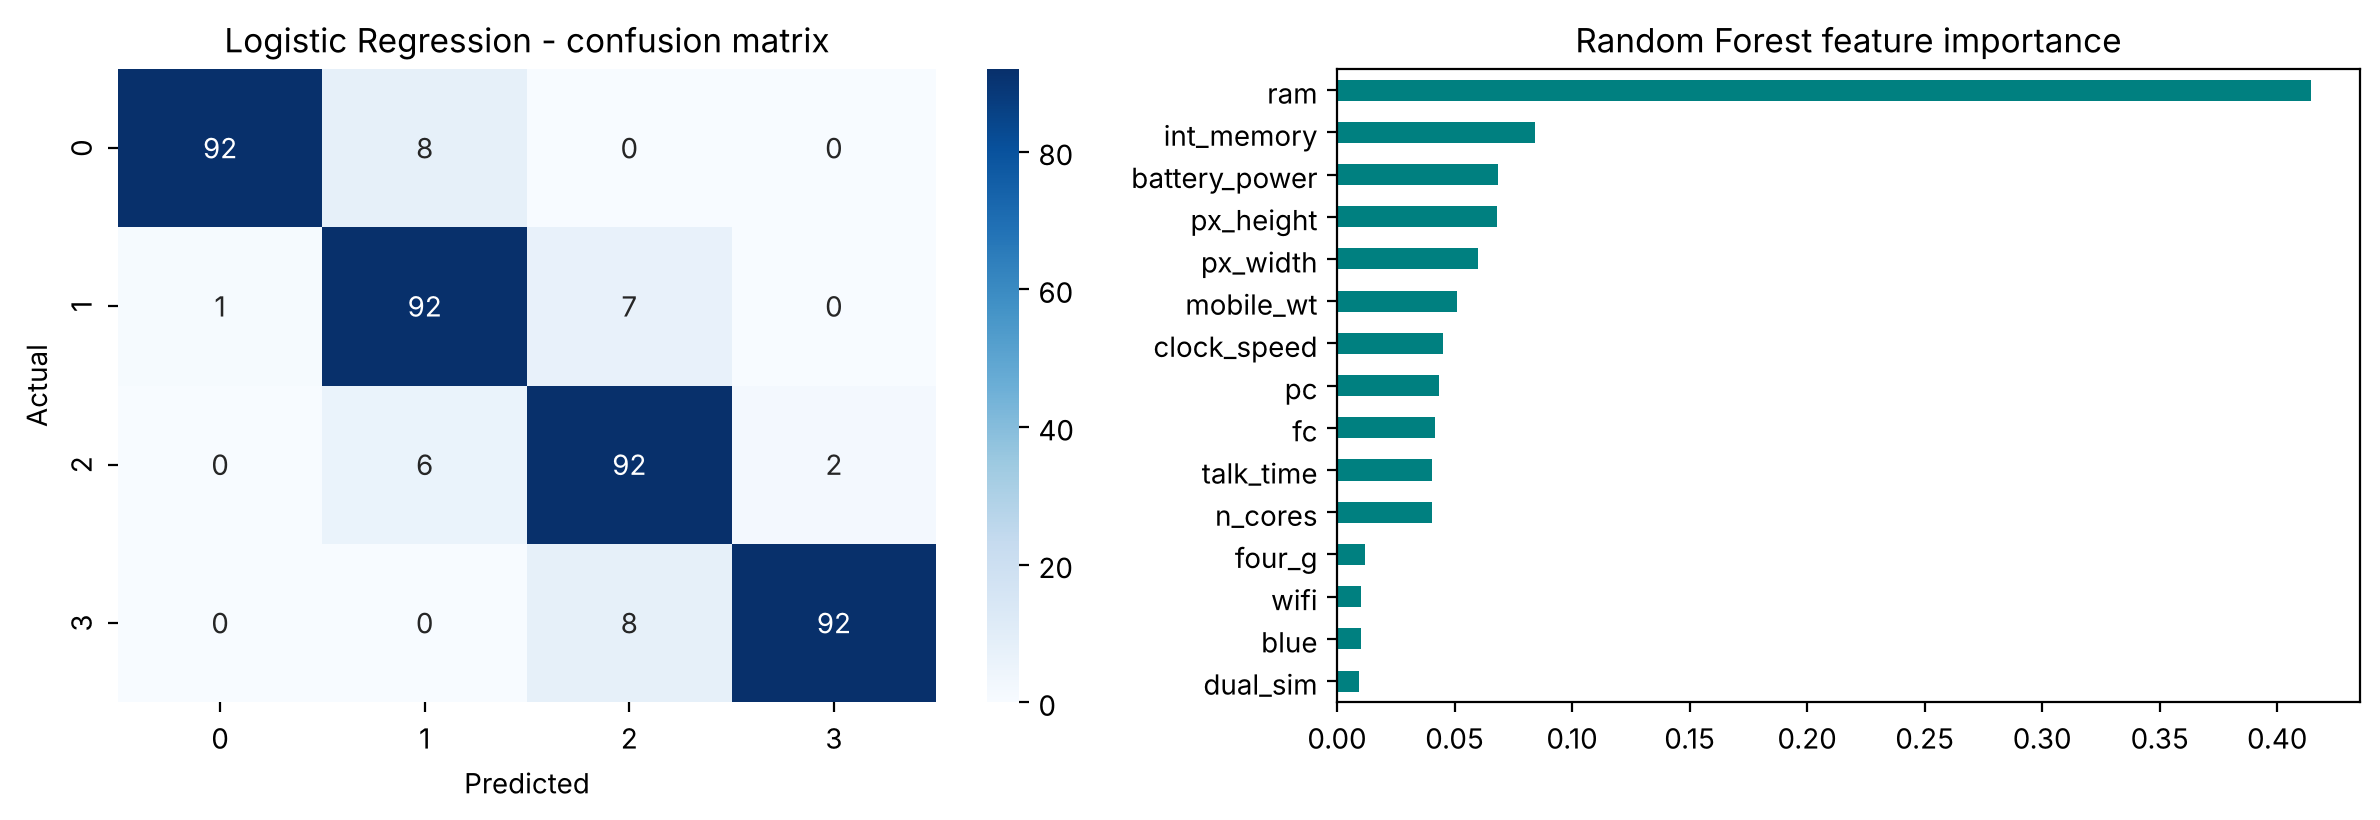

Top 5 features (Random Forest importance):
ram              0.414
int_memory       0.084
battery_power    0.069
px_height        0.068
px_width         0.060
Predicted price range for the new phone: 3 (0 = low ... 3 = very high)


In [4]:
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=['Low (0)', 'Medium (1)', 'High (2)', 'Very high (3)']))
print('Confusion matrix (rows = actual, cols = predicted):')
print(confusion_matrix(y_test, pred))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title(f'{best_name} - confusion matrix'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
rf = models['Random Forest']
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot.barh(ax=ax[1], color='teal')
ax[1].set_title('Random Forest feature importance'); plt.tight_layout(); plt.show()
print('Top 5 features (Random Forest importance):')
print(pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(5).round(3).to_string())

phone = pd.DataFrame([{'battery_power': 1800, 'blue': 1, 'clock_speed': 2.5, 'dual_sim': 1, 'fc': 8,
    'four_g': 1, 'int_memory': 48, 'mobile_wt': 140, 'n_cores': 8, 'pc': 16, 'px_height': 1500,
    'px_width': 1700, 'ram': 3500, 'talk_time': 12, 'wifi': 1}])
print('Predicted price range for the new phone:', best.predict(phone)[0], '(0 = low ... 3 = very high)')

## Result
RAM is by far the strongest price indicator, followed by internal memory, battery power and screen resolution. Logistic Regression is the best classifier here (about 92 % accuracy), and the confusion matrix shows that all its errors are between neighbouring price bands.